# SANDI: Nonlinear Optimisation and MCMC Fitting

This notebook demonstrates standard SANDI (Soma and Neurite Density Imaging) model fitting using two complementary approaches:
- **Nonlinear optimisation** (least-squares with multi-start): fast point estimate of parameters and residuals
- **MCMC sampling**: posterior uncertainty quantification and parameter correlations

We generate synthetic SANDI data and fit it using both methods to illustrate parameter identifiability challenges (e.g., soma radius–diffusivity degeneracy at fixed PGSE timing).

In [1]:
from pathlib import Path
import sys

def find_repo_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "src").exists():
            return candidate
    raise RuntimeError("Could not locate repository root containing src/.")

repo_root = find_repo_root(Path.cwd().resolve())
src_path = repo_root / "src"
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

import numpy as np
import matplotlib.pyplot as plt

from dmri_models import (
    Acquisition, Ball, Component, EmceeFitter, GaussianNoise,
    LeastSquaresFitter, Model, Sphere, Stick, sandi,
)
from dmri_models.acquisitions import sandi_full_acq

rng = np.random.default_rng(21)

## SANDI Model Overview

SANDI consists of three tissue compartments:

1. **Soma** (cell bodies): Restricted diffusion inside impermeable spheres, modelled using the Gamma Phase Distribution (GPD) approximation. Requires PGSE timing (pulse duration δ, diffusion time Δ, gradient strength G).

2. **Neurite** (axons and dendrites): Modelled as a powder-averaged (isotropic orientation distribution) stick with parallel diffusivity $d_{\parallel}$.

3. **Extra-axonal space**: Isotropic Gaussian compartment with diffusivity $d_{\text{ex}}$.

**Key parameter identifiability challenge**: At fixed PGSE timing, the soma radius $r$ and intra-soma diffusivity $d_s$ are highly correlated — different pairs $(r, d_s)$ can produce nearly identical signals. MCMC reveals this degeneracy through the posterior correlation structure.

## Acquisition and Synthetic Data

We use the standard Palombo SANDI acquisition scheme:
- **b-values**: 6 non-zero shells (0.5, 1.0, 2.0, 3.0, 4.0, 6.0 ms/µm²) with 50 directions each, plus 50 b=0 measurements
- **PGSE timing**: δ = 24 ms, Δ = 39 ms (soma-sensitive diffusion imaging)
- **Total**: 350 measurements

SNR = 500 (σ = 0.002) matches the noise level used in the original Palombo et al. study. This is required for stable NL fitting with free diffusivities. At SNR = 100 (σ = 0.01), d_in becomes poorly constrained and the NL optimizer finds degenerate solutions.

### Simulation and spherical mean workflow

SANDI is designed for **gray matter**, where neurites have no preferred orientation. All three SANDI compartments (sphere, powder-averaged stick, ball) are isotropic, so the measured signal is the same across gradient directions within a shell. The correct procedure is:

1. **Simulate** with the powder-averaged SANDI model across all 350 measurements (same expected signal per shell, independent noise)
2. **Add noise** independently to each measurement
3. **Average** per b-shell → spherical mean (reduces noise by $\sqrt{N_\text{dirs}} = \sqrt{50} \approx 7$, giving effective SNR ≈ 3500 per shell)
4. **Fit** the powder-averaged model to the shell-averaged data

With 6 non-zero b-shells and 6 free parameters, the system has exactly 1 degree of freedom at the spherical mean level. NL fitting and MCMC both operate on the 7 spherical mean values.

In [3]:
# Full directional acquisition (Palombo SANDI scheme: 7 shells, 60 directions each)
acquisition = sandi_full_acq()

# Noise level: SNR = S0 / sigma (per directional measurement)
S0 = 1.0
SNR = 500
sigma = S0 / SNR  

# Ground-truth parameters
true_parameters = {
    "S0": S0,
    "r_soma": 7.0,
    "d_in": 2.0,
    "d_ex": 1.5,
    "d_sphere": 3.0,
    "soma_fraction": 0.22,
    "neurite_fraction": 0.50,
    "extra_fraction": 0.28,
}

# Simulate with powder-averaged SANDI model (all compartments isotropic)
sim_preset = sandi(
    d_sphere=true_parameters["d_sphere"],
    d_in=true_parameters["d_in"],
    d_ex=true_parameters["d_ex"],
)
signal_sim = sim_preset.model.signal(acquisition, true_parameters)

# Add independent Gaussian noise to each directional measurement
signal_noisy = signal_sim + rng.normal(0.0, sigma, size=signal_sim.shape)

# --- Compute spherical mean per b-shell ---
b_vals = acquisition.b_values
b_shells = np.unique(np.round(b_vals, 4))

sm_signals, sm_b_values, n_dirs_per_shell = [], [], []
for b in b_shells:
    mask = np.abs(b_vals - b) < 1e-4
    sm_signals.append(np.mean(signal_noisy[mask]))
    sm_b_values.append(b)
    n_dirs_per_shell.append(mask.sum())

sm_signal = np.array(sm_signals)
sm_b_values = np.array(sm_b_values)
n_dirs = np.array(n_dirs_per_shell)
sigma_sm = sigma / np.sqrt(n_dirs)  # Noise on spherical mean

# Compact spherical mean acquisition (one measurement per shell)
acq_sm = Acquisition.from_pgse(
    sm_b_values,
    b_unit="ms/um^2",
    pulse_duration=acquisition.pulse_duration[0],
    diffusion_time=acquisition.diffusion_time[0],
    b_tensor_shape=acquisition.b_tensor_shape[0],
)

print(f"Directional acquisition:    {acquisition.n_measurements} measurements")
print(f"Spherical mean acquisition: {acq_sm.n_measurements} measurements (1 per b-shell)")
print(f"b-shells (ms/µm²): {sm_b_values}")
print(f"Dirs per shell:    {n_dirs}")
print(f"SNR per direction: {SNR:.0f}  |  SNR of spherical mean ({n_dirs[0]} dirs): {SNR*np.sqrt(n_dirs[0]):.0f}")

Directional acquisition:    170 measurements
Spherical mean acquisition: 6 measurements (1 per b-shell)
b-shells (ms/µm²): [0.  0.5 1.  2.  3.  6. ]
Dirs per shell:    [20 30 30 30 30 30]
SNR per direction: 500  |  SNR of spherical mean (20 dirs): 2236


## Nonlinear Optimisation (Least-Squares)

We fit the powder-averaged SANDI model to the spherical mean measurements. With 6 non-zero b-shells the system is well-determined, so **all diffusivities are free** alongside r_soma and the volume fractions. Free parameters:
- **S₀**, **r_soma**, **d_in**, **d_ex**: 4 continuous parameters
- **soma_fraction**, **neurite_fraction** (extra_fraction = 1 − soma − neurite): 2 free fractions

That gives 6 unknowns from 7 spherical mean data points (1 degree of freedom). Multi-start optimisation is used to guard against local minima.

> **Limitation**: NL least-squares is a fast approximation and can get stuck in local minima. At lower SNR (e.g. σ = 0.01), d_in tends to hit its parameter bound — a sign that the optimizer found a degenerate solution rather than the true minimum. The MCMC section below provides the principled alternative.

In [23]:
# All diffusivities free — well-determined with 6 non-zero shells
preset_nl = sandi(
    vary_sphere_diffusivity=False,   # d_sphere still fixed (free water at body temp)
    vary_neurite_diffusivity=True,
    vary_extra_diffusivity=True,
    d_sphere=true_parameters["d_sphere"],
    d_in=true_parameters["d_in"],    # Initial value
    d_ex=true_parameters["d_ex"],    # Initial value
)

fitter_ls = LeastSquaresFitter(preset_nl.model, preset_nl.parameters)
fit_ls = fitter_ls.fit(
    acq_sm,
    sm_signal,
    n_starts=10,
    max_nfev=2000,
    rng=rng,
)

print(f"Least-squares fit (d_sphere fixed at {true_parameters['d_sphere']}, d_in and d_ex free):")
print(f"  Success: {fit_ls.success}")
print(f"  Cost:    {fit_ls.cost:.6f}")

print("\nParameter recovery (NL optimisation — spherical mean):")
print(f"{'Parameter':<20} {'True':>10} {'Fit':>10} {'Error':>10}")
print("-" * 50)
for param in ["r_soma", "d_in", "d_ex", "soma_fraction", "neurite_fraction"]:
    true_val = true_parameters[param]
    fit_val = fit_ls.parameters[param]
    print(f"{param:<20} {true_val:>10.4f} {fit_val:>10.4f} {fit_val - true_val:>10.4f}")

residuals_ls = sm_signal - fit_ls.predicted_signal
print(f"\nRMSE: {np.sqrt(np.mean(residuals_ls**2)):.6f}")
print(f"Noise floor (sigma_sm mean): {sigma_sm.mean():.6f}")

Least-squares fit (d_sphere fixed at 3.0, d_in and d_ex free):
  Success: True
  Cost:    0.000000

Parameter recovery (NL optimisation — spherical mean):
Parameter                  True        Fit      Error
--------------------------------------------------
r_soma                   7.0000     6.6436    -0.3564
d_in                     2.0000     2.4615     0.4615
d_ex                     1.5000     1.3005    -0.1995
soma_fraction            0.2200     0.2484     0.0284
neurite_fraction         0.5000     0.4586    -0.0414

RMSE: 0.000043
Noise floor (sigma_sm mean): 0.000258


## MCMC Sampling: Posterior Uncertainty and Parameter Correlations

With d_sphere fixed (as in the NL fit), MCMC explores the full posterior over r_soma, d_in, d_ex, and the volume fractions. This reveals:

- **Posterior uncertainty**: credible intervals for all free parameters
- **Parameter correlations**: trade-offs between r_soma, d_in, d_ex, and fractions
- **Identifiability**: which parameters are well-constrained at this SNR and acquisition

We use ensemble MCMC (emcee) with 32 walkers and 900 iterations (300 burn-in, retain every 2nd sample).

In [24]:
# MCMC: d_sphere fixed (assumed known), d_in and d_ex free — matches the NL fit approach
preset_mcmc = sandi(
    vary_sphere_diffusivity=False,
    vary_neurite_diffusivity=True,
    vary_extra_diffusivity=True,
    d_sphere=true_parameters["d_sphere"],
    d_in=true_parameters["d_in"],
    d_ex=true_parameters["d_ex"],
)

sigma_sm_mean = sigma_sm.mean()
fitter_mcmc = EmceeFitter(preset_mcmc.model, preset_mcmc.parameters, GaussianNoise(sigma=sigma_sm_mean))
result = fitter_mcmc.sample(
    acq_sm,
    sm_signal,
    n_steps=900,
    burn_in=300,
    thin=2,
    n_walkers=32,
    rng=rng,
    progress=False,
)

print(f"MCMC sampling complete (d_sphere fixed, d_in and d_ex free):")
print(f"  Mean acceptance fraction: {result.acceptance_fraction.mean():.3f}")
print(f"  Per-walker acceptance: min={result.acceptance_fraction.min():.3f}, max={result.acceptance_fraction.max():.3f}")

MCMC sampling complete (d_sphere fixed, d_in and d_ex free):
  Mean acceptance fraction: 0.175
  Per-walker acceptance: min=0.018, max=0.231


In [25]:
# Summarise posterior statistics
print("Posterior summary (MCMC, d_sphere fixed):")
print(f"{'Parameter':<20} {'True':>10} {'Mean':>10} {'SD':>10} {'95% CI':<20}")
print("-" * 70)

summary = result.summary()
for name, stats in summary.items():
    true_val = true_parameters.get(name, np.nan)
    ci = f"({stats['lower']:.4f}, {stats['upper']:.4f})"
    print(
        f"{name:<20} {true_val:>10.4f} {stats['mean']:>10.4f} {stats['sd']:>10.4f} {ci:<20}"
    )

Posterior summary (MCMC, d_sphere fixed):
Parameter                  True       Mean         SD 95% CI              
----------------------------------------------------------------------
S0                       1.0000     0.9991     0.0038 (0.9787, 1.0012)    
r_soma                   7.0000     8.9833     2.6960 (6.5503, 14.0247)   
d_in                     2.0000     2.1021     0.5726 (0.1366, 2.7757)    
d_ex                     1.5000     1.1024     0.5048 (0.1228, 1.6207)    
d_sphere                 3.0000     3.0000     0.0000 (3.0000, 3.0000)    
soma_fraction            0.2200     0.1722     0.1465 (0.0031, 0.7022)    
neurite_fraction         0.5000     0.5688     0.2090 (0.0310, 0.8265)    
extra_fraction           0.2800     0.2590     0.0872 (0.0186, 0.4133)    


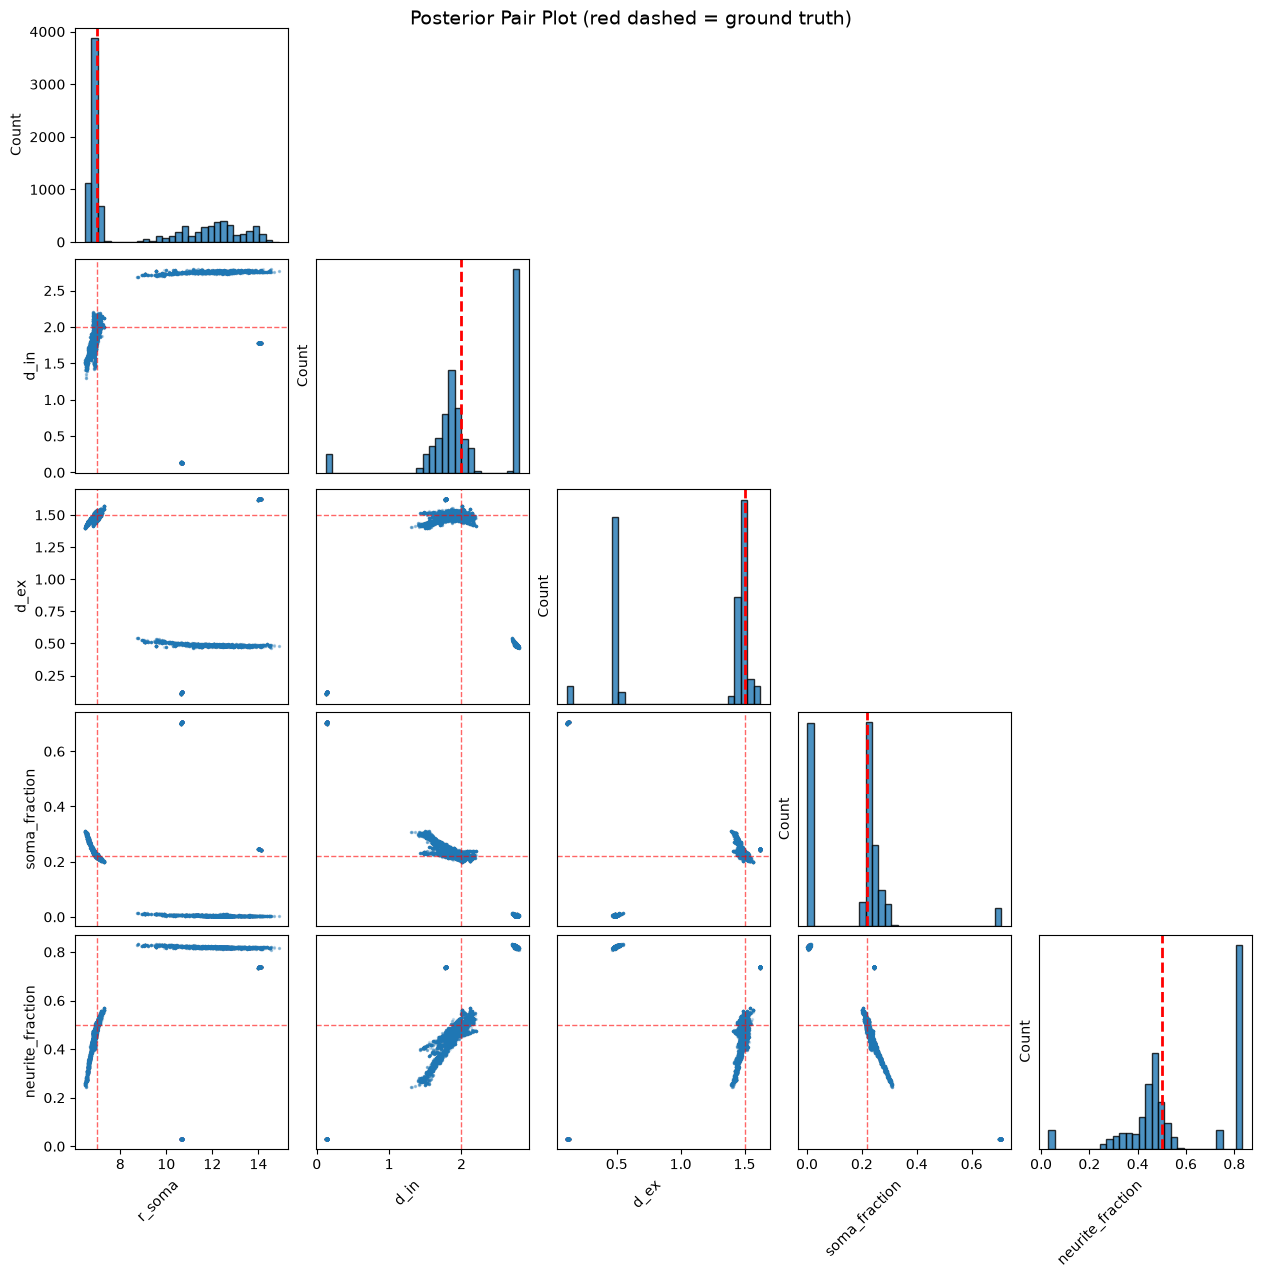

In [26]:
# Extract posterior samples and build pair plot
samples = result.physical_samples(flat=True)
names = [
    "r_soma",
    "d_in",
    "d_ex",
    "soma_fraction",
    "neurite_fraction",
]
X = np.vstack([samples[name] for name in names]).T

# Pair plot (lower triangle = scatter, diagonal = histogram, upper = off)
n = len(names)
fig, axes = plt.subplots(n, n, figsize=(2.5 * n, 2.5 * n), constrained_layout=True)
for i in range(n):
    for j in range(n):
        ax = axes[i, j]
        if i == j:
            ax.hist(X[:, j], bins=30, color="tab:blue", alpha=0.8, edgecolor="black")
            ax.axvline(true_parameters[names[j]], color="red", linestyle="--", linewidth=2)
            ax.set_ylabel("Count")
        elif i > j:
            ax.scatter(X[:, j], X[:, i], s=2, alpha=0.2, color="tab:blue")
            ax.axvline(true_parameters[names[j]], color="red", linestyle="--", linewidth=1, alpha=0.6)
            ax.axhline(true_parameters[names[i]], color="red", linestyle="--", linewidth=1, alpha=0.6)
        else:
            ax.axis("off")

        if i == n - 1:
            ax.set_xlabel(names[j], rotation=45, ha="right")
        else:
            ax.set_xticks([])
        if j == 0 and i > 0:
            ax.set_ylabel(names[i])
        elif j != 0:
            ax.set_yticks([])

fig.suptitle("Posterior Pair Plot (red dashed = ground truth)", y=1.01, fontsize=14)
plt.show()

## Posterior Visualisation and Parameter Correlations

The pair plot (lower triangle) reveals the joint posterior for key parameters. **Strong correlations indicate parameter degeneracy**: different parameter combinations produce similarly good fits to the data.

Expected pattern: **soma radius ↔ soma diffusivity** should show strong negative correlation (large radius + low diffusivity ≈ small radius + high diffusivity). Other parameters may also show weaker correlations due to volume fraction trade-offs.

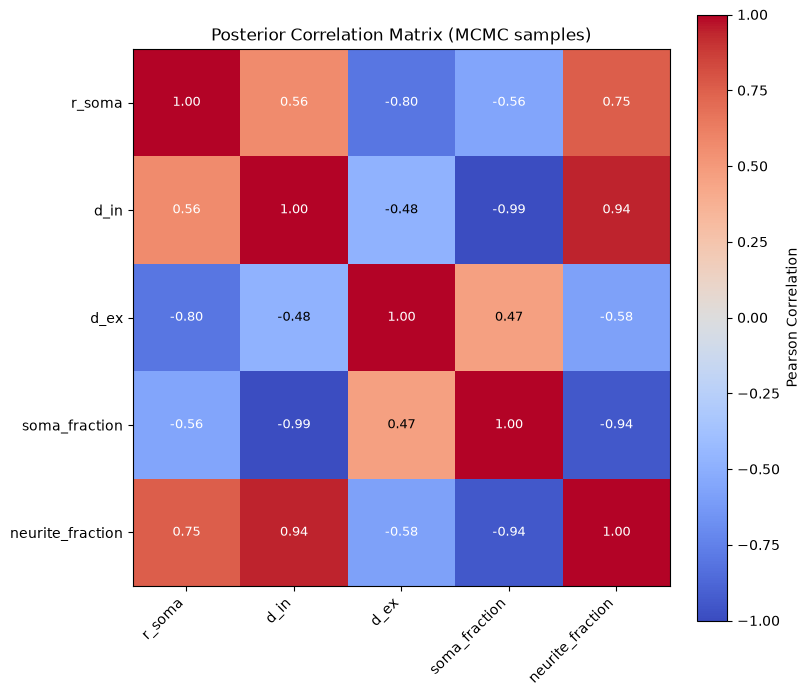


Strong posterior correlations (|r| > 0.7):
(These indicate fundamental parameter degeneracy)
  r_soma          ↔ d_ex           :  -0.803
  r_soma          ↔ neurite_fraction:   0.755
  d_in            ↔ soma_fraction  :  -0.987
  d_in            ↔ neurite_fraction:   0.944
  soma_fraction   ↔ neurite_fraction:  -0.940


In [27]:
# Posterior correlation matrix
corr = np.corrcoef(X.T)

fig, ax = plt.subplots(figsize=(8, 7), constrained_layout=True)
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(names)))
ax.set_yticks(range(len(names)))
ax.set_xticklabels(names, rotation=45, ha="right")
ax.set_yticklabels(names)

# Add correlation values as text
for i in range(len(names)):
    for j in range(len(names)):
        text_color = "white" if abs(corr[i, j]) > 0.5 else "black"
        ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", fontsize=9, color=text_color)

ax.set_title("Posterior Correlation Matrix (MCMC samples)", fontsize=12)
fig.colorbar(im, ax=ax, label="Pearson Correlation")
plt.show()

# Identify strong correlations (|r| > 0.7)
print("\nStrong posterior correlations (|r| > 0.7):")
print("(These indicate fundamental parameter degeneracy)")
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        if abs(corr[i, j]) > 0.7:
            print(f"  {names[i]:15s} ↔ {names[j]:15s}: {corr[i, j]:7.3f}")

## Summary: NL Optimisation vs MCMC

Both the NL fit and MCMC use the same model: **d_sphere is fixed** at the assumed free-water diffusivity value (3.0 µm²/ms), while r_soma, d_in, d_ex, and volume fractions are all free.

**Nonlinear least-squares**:
- Fast point estimate (seconds)
- Fits the spherical mean (7 data points) with multi-start optimisation
- Works reliably only at high SNR (σ ≲ 0.002, i.e. SNR ≳ 500 per measurement)
- At lower SNR, d_in / d_ex become underdetermined and the optimizer finds degenerate solutions
- Should be treated as a fast initialisation, not a reliable estimator

**MCMC sampling**:
- Full posterior distribution (minutes)
- Robust across a wider range of SNR — explores the posterior rather than minimising a cost
- Credible intervals and uncertainty quantification for all parameters
- Reveals parameter correlations (e.g. r_soma ↔ d_in ↔ fraction trade-offs)
- The principled tool for SANDI parameter estimation

**Why noise matters so much**: SANDI has 7 independent b-shell measurements and 6 free parameters (1 degree of freedom). The chi-squared landscape is very flat, and small noise fluctuations can steer the NL optimizer into a degenerate basin (e.g. high d_in + low f_neurite). MCMC marginalises over this uncertainty correctly.

**d_sphere convention**: fixing d_sphere at the free-water diffusivity (≈ 3.0 µm²/ms at 37°C) is standard practice in SANDI. It avoids the fundamental r_soma–d_sphere degeneracy that would otherwise make soma radius unidentifiable.